In [1]:
# torch and torchvision are already provided by the HPC environment.
%pip -q install scikit-learn scikit-image pandas matplotlib seaborn tqdm pillow


Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import random
import copy
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import (
    ResNet18_Weights,
    VGG16_Weights
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not available.")

PyTorch version: 2.13.0
Device: cuda
GPU: NVIDIA A40


In [2]:
from pathlib import Path

# ---------------------------------------------------------------
# All paths are RELATIVE to the directory containing this notebook.
# Start Jupyter from the notebook's folder (the default on the HPC)
# so that these paths resolve correctly.
# ---------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

# Cats vs Dogs dataset stored next to the notebook:
#   <notebook dir>/data/dogs-vs-cats-classification
DATA_ROOT = PROJECT_ROOT / "data" / "dogs-vs-cats-classification"

# SRGAN output directories, created next to the notebook
PROJECT_DIR = PROJECT_ROOT / "SRGAN_Midterm"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for folder in [
    PROJECT_DIR,
    CHECKPOINT_DIR,
    RESULTS_DIR,
    FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Verify dataset
print("Dataset exists:", DATA_ROOT.exists())
print("Dataset path:", DATA_ROOT)

if DATA_ROOT.exists():
    print("\nDataset contents:")
    for item in DATA_ROOT.iterdir():
        print(item.name)
else:
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_ROOT}"
    )


Dataset exists: True
Dataset path: /users/sbandyop/repositories/test/Applied_AI_midterm_files/data/dogs-vs-cats-classification

Dataset contents:
test
.DS_Store
dataset_info.csv
validation
train


In [3]:
# =====================================================
# BLOCK 4: LOAD CATS VS DOGS DATASET
# =====================================================

import pandas as pd
from pathlib import Path

print("Dataset location:", DATA_ROOT)

def identify_label(path):

    filename = path.name.lower()

    # Standard Kaggle image filenames
    if filename.startswith(("cat.", "cat_", "cat-")):
        return 0

    elif filename.startswith(("dog.", "dog_", "dog-")):
        return 1

    # Folder-based labels
    for parent in path.parents:

        if parent == DATA_ROOT.parent:
            break

        folder_name = parent.name.lower()

        if folder_name in ["cat", "cats"]:
            return 0

        elif folder_name in ["dog", "dogs"]:
            return 1

    return None


image_extensions = [
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
]

records = []

for path in DATA_ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in image_extensions:
        continue

    label = identify_label(path)

    if label is not None:

        records.append({
            "path": str(path),
            "label": label
        })


df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError(
        "No labeled Cats vs Dogs images found. "
        "Check your dataset folder structure."
    )

df = df.drop_duplicates(
    subset="path"
).reset_index(drop=True)


print("\n================================")
print("DATASET INFORMATION")
print("================================")

print("Total images:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

print("\nSample image paths:")
display(df.head())

Dataset location: /users/sbandyop/repositories/test/Applied_AI_midterm_files/data/dogs-vs-cats-classification

DATASET INFORMATION
Total images: 13288

Class distribution:
label
0    6976
1    6312
Name: count, dtype: int64

Sample image paths:


,path,label
0,/users/sbandyop/repositories/test/Applied_AI_m...,0
1,/users/sbandyop/repositories/test/Applied_AI_m...,0
2,/users/sbandyop/repositories/test/Applied_AI_m...,0
3,/users/sbandyop/repositories/test/Applied_AI_m...,0
4,/users/sbandyop/repositories/test/Applied_AI_m...,0


In [4]:
# =====================================================
# BLOCK 5: DATASET SPLITTING
# =====================================================

from sklearn.model_selection import train_test_split

SEED = 42

# First split: 70% training / 30% testing
trainval_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

# Validation is taken from training portion
train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.10,
    random_state=SEED,
    stratify=trainval_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


print("================================")
print("DATASET SPLIT")
print("================================")

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# Verify that no image path appears in multiple splits

assert set(train_df["path"]).isdisjoint(
    val_df["path"]
)

assert set(train_df["path"]).isdisjoint(
    test_df["path"]
)

assert set(val_df["path"]).isdisjoint(
    test_df["path"]
)

# Save split information

train_df.to_csv(
    PROJECT_DIR / "train_split.csv",
    index=False
)

val_df.to_csv(
    PROJECT_DIR / "val_split.csv",
    index=False
)

test_df.to_csv(
    PROJECT_DIR / "test_split.csv",
    index=False
)

print("\nDataset split saved successfully.")

DATASET SPLIT
Total images: 13288
Training images: 8370
Validation images: 931
Testing images: 3987

Dataset split saved successfully.


In [5]:
# =====================================================
# BLOCK 6: COMPLETE DATASET AND DATALOADER SETUP
# =====================================================

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageFile
from pathlib import Path

import warnings

ImageFile.LOAD_TRUNCATED_IMAGES = True

warnings.filterwarnings(
    "ignore",
    message="Truncated File Read",
    category=UserWarning
)

# =====================================================
# 1. CONFIGURATION
# =====================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IMG_SIZE = 128
LR_SIZE = 32

BATCH_CLS = 32
BATCH_GAN = 16

NUM_WORKERS = 0

print("Device:", device)

# =====================================================
# 2. IMAGE TRANSFORMATIONS
# =====================================================

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# =====================================================
# 3. CUSTOM DATASET CLASS
# =====================================================

class CatsDogsDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.paths = dataframe["path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        image_path = self.paths[idx]
        label = self.labels[idx]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )

# =====================================================
# 4. CREATE DATASETS
# =====================================================

train_dataset = CatsDogsDataset(
    train_df,
    transform=train_transform
)

val_dataset = CatsDogsDataset(
    val_df,
    transform=test_transform
)

test_dataset = CatsDogsDataset(
    test_df,
    transform=test_transform
)

print("\nDatasets created successfully.")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# =====================================================
# 5. CREATE CLASSIFIER DATALOADERS
# =====================================================

train_loader_cls = DataLoader(
    train_dataset,
    batch_size=BATCH_CLS,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader_cls = DataLoader(
    val_dataset,
    batch_size=BATCH_CLS,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader_cls = DataLoader(
    test_dataset,
    batch_size=BATCH_CLS,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

# =====================================================
# 6. CREATE SRGAN DATALOADERS
# =====================================================

train_loader_gan = DataLoader(
    train_dataset,
    batch_size=BATCH_GAN,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader_gan = DataLoader(
    val_dataset,
    batch_size=BATCH_GAN,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader_gan = DataLoader(
    test_dataset,
    batch_size=BATCH_GAN,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

# =====================================================
# 7. VERIFY DATALOADERS
# =====================================================

images, labels = next(iter(train_loader_cls))

print("\n================================")
print("DATALOADER VERIFICATION")
print("================================")

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Number of classifier batches:", len(train_loader_cls))
print("Number of SRGAN batches:", len(train_loader_gan))

print("\nBlock 6 completed successfully!")

Device: cuda

Datasets created successfully.
Training samples: 8370
Validation samples: 931
Testing samples: 3987

DATALOADER VERIFICATION
Images shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])
Number of classifier batches: 262
Number of SRGAN batches: 524

Block 6 completed successfully!


In [6]:
# =====================================================
# TEST DATALOADER
# =====================================================

from tqdm.auto import tqdm

num_batches_tested = 0

for images, labels in tqdm(
    train_loader_cls,
    desc="Testing DataLoader"
):
    num_batches_tested += 1

    if num_batches_tested >= 20:
        break

print("Successfully loaded", num_batches_tested, "batches")
print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Testing DataLoader:   0%|          | 0/262 [00:00<?, ?it/s]

Successfully loaded 20 batches
Image shape: torch.Size([32, 3, 128, 128])
Label shape: torch.Size([32])


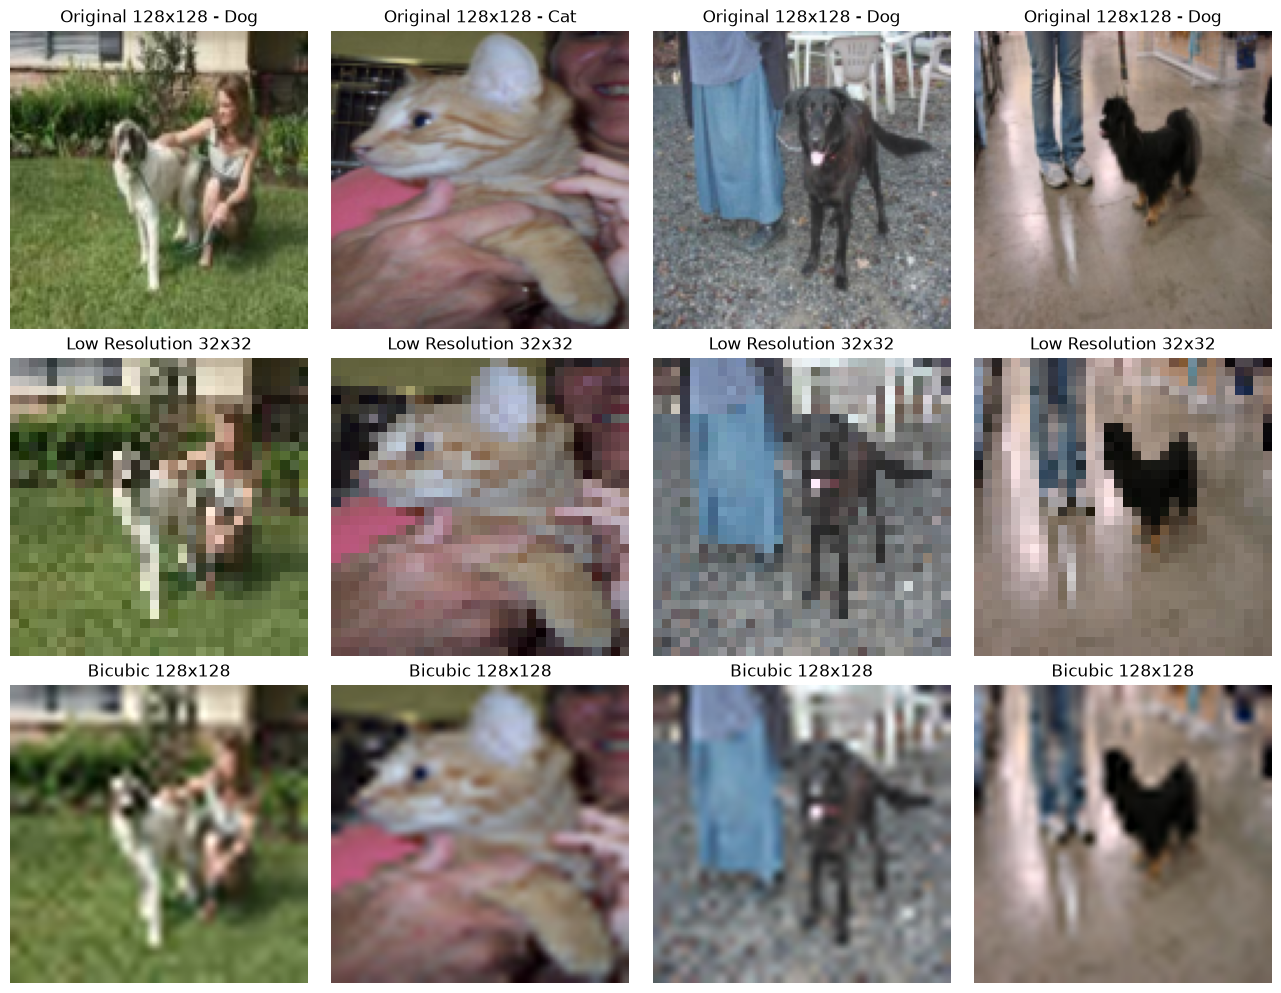

In [7]:
# =====================================================
# BLOCK 7: VISUALIZE IMAGE TRANSFORMATIONS
# =====================================================

import matplotlib.pyplot as plt
import torch.nn.functional as F

images, labels = next(iter(train_loader_cls))

fig, axes = plt.subplots(
    3, 4,
    figsize=(13, 10)
)

for i in range(4):

    hr = images[i]

    # Downscale 128x128 -> 32x32
    lr = F.interpolate(
        hr.unsqueeze(0),
        size=(32, 32),
        mode="bicubic",
        align_corners=False
    ).squeeze(0).clamp(0, 1)

    # Ordinary bicubic upscale
    bicubic = F.interpolate(
        lr.unsqueeze(0),
        size=(128, 128),
        mode="bicubic",
        align_corners=False
    ).squeeze(0).clamp(0, 1)

    label_name = (
        "Cat" if labels[i].item() == 0 else "Dog"
    )

    axes[0, i].imshow(
        hr.permute(1, 2, 0)
    )

    axes[1, i].imshow(
        lr.permute(1, 2, 0)
    )

    axes[2, i].imshow(
        bicubic.permute(1, 2, 0)
    )

    axes[0, i].set_title(
        f"Original 128x128 - {label_name}"
    )

    axes[1, i].set_title(
        "Low Resolution 32x32"
    )

    axes[2, i].set_title(
        "Bicubic 128x128"
    )

    for row in range(3):
        axes[row, i].axis("off")


plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "image_transformations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
# =====================================================
# BLOCK 8: BUILD CLASSIFIER A
# =====================================================

import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights


# ImageNet normalization
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(1, 3, 1, 1).to(device)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(1, 3, 1, 1).to(device)


def normalize_imagenet(images):

    return (
        images - IMAGENET_MEAN
    ) / IMAGENET_STD


def create_classifier():

    model = models.resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    # Freeze pretrained feature extractor
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Replace classification head
    in_features = model.fc.in_features

    model.fc = nn.Sequential(

        nn.Linear(in_features, 128),

        nn.ReLU(),

        nn.Dropout(0.3),

        nn.Linear(128, 2)

    )

    return model.to(device)


classifier_A = create_classifier()

print("Classifier A created successfully.")

print("\nClassification head:")
print(classifier_A.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /users/sbandyop/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 301MB/s]


Classifier A created successfully.

Classification head:
Sequential(
  (0): Linear(in_features=512, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=2, bias=True)
)


In [9]:
# =====================================================
# BLOCK 9: CLASSIFIER TRAINING FUNCTIONS
# =====================================================

import torch.optim as optim
from tqdm.auto import tqdm


def get_classifier_inputs(images, generator=None):

    if generator is None:

        return normalize_imagenet(images)

    # Used later for Classifier B
    with torch.no_grad():

        lr = F.interpolate(
            images,
            size=(LR_SIZE, LR_SIZE),
            mode="bicubic",
            align_corners=False
        ).clamp(0, 1)

        sr = generator(lr * 2 - 1)

        sr = ((sr + 1) / 2).clamp(0, 1)

    return normalize_imagenet(sr)


def train_classifier_epoch(
    model,
    loader,
    optimizer,
    criterion,
    generator=None
):

    model.train()

    # Keep the frozen ResNet backbone's BatchNorm
    # statistics fixed during transfer learning.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    if generator is not None:
        generator.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for images, labels in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        inputs = get_classifier_inputs(
            images,
            generator
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(inputs)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        predictions = outputs.argmax(dim=1)

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


@torch.no_grad()
def validate_classifier(
    model,
    loader,
    criterion,
    generator=None
):

    model.eval()

    if generator is not None:
        generator.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        inputs = get_classifier_inputs(
            images,
            generator
        )

        outputs = model(inputs)

        loss = criterion(
            outputs,
            labels
        )

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        predictions = outputs.argmax(dim=1)

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


def fit_classifier(
    model,
    train_loader,
    val_loader,
    epochs,
    checkpoint_path,
    generator=None
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=1e-4
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    checkpoint_path = Path(checkpoint_path)

    best_path = checkpoint_path.with_name(
        checkpoint_path.stem + "_best.pth"
    )

    start_epoch = 0
    best_val_acc = -1.0

    # Resume training
    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(
            checkpoint["model"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer"]
        )

        start_epoch = checkpoint["epoch"]

        history = checkpoint["history"]

        best_val_acc = checkpoint["best_val_acc"]

        print(
            "Resuming training from epoch:",
            start_epoch
        )

    # Training loop
    for epoch in range(start_epoch, epochs):

        train_loss, train_acc = train_classifier_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            generator
        )

        val_loss, val_acc = validate_classifier(
            model,
            val_loader,
            criterion,
            generator
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Save best-performing model
        if val_acc > best_val_acc:

            best_val_acc = val_acc

            torch.save(
                model.state_dict(),
                best_path
            )

        # Save resumable checkpoint every epoch
        checkpoint = {
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "best_val_acc": best_val_acc
        }

        torch.save(
            checkpoint,
            checkpoint_path
        )

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    # Load best weights before final evaluation
    model.load_state_dict(
        torch.load(
            best_path,
            map_location=device,
            weights_only=True
        )
    )

    return model, history

In [10]:
# =====================================================
# BLOCK 10: TRAIN CLASSIFIER A
# =====================================================

CLS_EPOCHS = 10

classifier_A, history_A = fit_classifier(

    model=classifier_A,

    train_loader=train_loader_cls,

    val_loader=val_loader_cls,

    epochs=CLS_EPOCHS,

    checkpoint_path=(
        CHECKPOINT_DIR / "classifier_A_latest.pth"
    )

)

print("\nClassifier A training completed.")

Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 0.1973 | Train Acc: 0.9196 | Val Loss: 0.1129 | Val Acc: 0.9570


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [2/10] | Train Loss: 0.1171 | Train Acc: 0.9519 | Val Loss: 0.1009 | Val Acc: 0.9646


Training:   0%|          | 0/262 [00:00<?, ?it/s]

...

Epoch [8/10] | Train Loss: 0.0857 | Train Acc: 0.9673 | Val Loss: 0.0924 | Val Acc: 0.9635


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.0826 | Train Acc: 0.9680 | Val Loss: 0.0918 | Val Acc: 0.9581


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.0796 | Train Acc: 0.9698 | Val Loss: 0.0913 | Val Acc: 0.9656

Classifier A training completed.


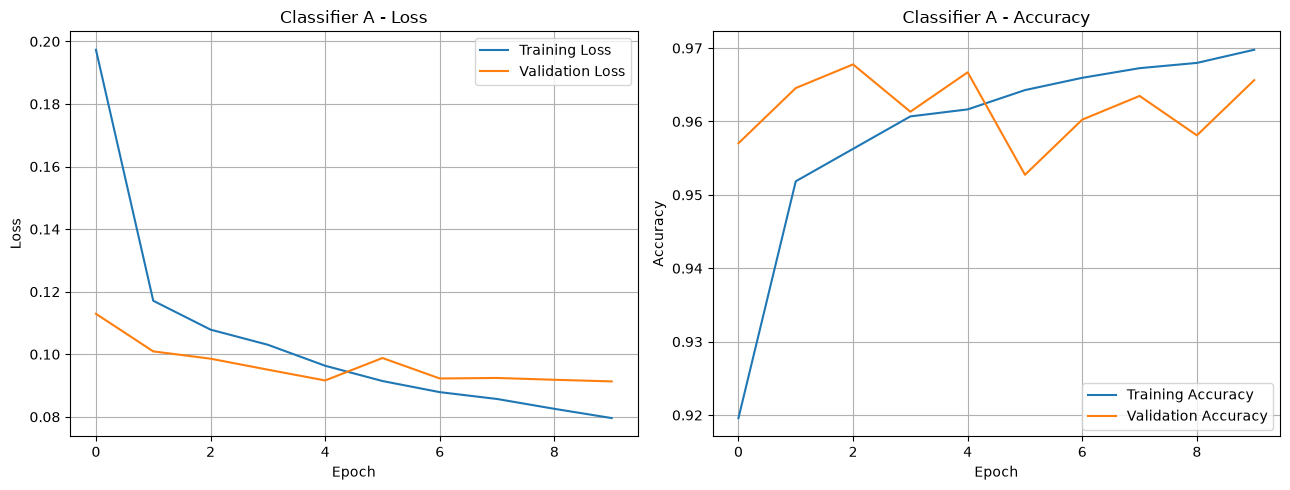

In [11]:
# =====================================================
# BLOCK 10B: PLOT CLASSIFIER A PERFORMANCE
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].plot(
    history_A["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_A["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Classifier A - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    history_A["train_acc"],
    label="Training Accuracy"
)

axes[1].plot(
    history_A["val_acc"],
    label="Validation Accuracy"
)

axes[1].set_title("Classifier A - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "classifier_A_training.png",
    dpi=200
)

plt.show()

In [12]:
from pathlib import Path

best_A_path = (
    CHECKPOINT_DIR / "classifier_A_latest_best.pth"
)

print("Best Classifier A saved:", best_A_path.exists())

Best Classifier A saved: True


In [13]:
classifier_A.load_state_dict(
    torch.load(
        best_A_path,
        map_location=device,
        weights_only=True
    )
)

classifier_A.eval()

print("Best Classifier A loaded successfully.")

Best Classifier A loaded successfully.


In [14]:
# =====================================================
# BLOCK 11: SRGAN GENERATOR
# =====================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class ResidualBlock(nn.Module):

    def __init__(self, channels=64):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                channels, channels,
                kernel_size=3, stride=1, padding=1
            ),
            nn.BatchNorm2d(channels),
            nn.PReLU(),

            nn.Conv2d(
                channels, channels,
                kernel_size=3, stride=1, padding=1
            ),
            nn.BatchNorm2d(channels)
        )

    def forward(self, x):
        return x + self.block(x)


class UpsampleBlock(nn.Module):

    def __init__(self, channels=64):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                channels, channels * 4,
                kernel_size=3, padding=1
            ),
            nn.PixelShuffle(2),
            nn.PReLU()
        )

    def forward(self, x):
        return self.block(x)


class Generator(nn.Module):

    def __init__(self, num_residual_blocks=8):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.PReLU()
        )

        self.residual_blocks = nn.Sequential(
            *[
                ResidualBlock(64)
                for _ in range(num_residual_blocks)
            ]
        )

        self.post_residual = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64)
        )

        self.upsampling = nn.Sequential(
            UpsampleBlock(64),
            UpsampleBlock(64)
        )

        self.output = nn.Sequential(
            nn.Conv2d(64, 3, kernel_size=9, padding=4),
            nn.Tanh()
        )

    def forward(self, x):

        x_initial = self.initial(x)

        x_residual = self.residual_blocks(x_initial)
        x_residual = self.post_residual(x_residual)

        x = x_initial + x_residual

        x = self.upsampling(x)

        return self.output(x)


# Initialize generator
generator = Generator().to(device)

# Verify dimensions
generator.eval()

with torch.no_grad():
    dummy_lr = torch.randn(1, 3, 32, 32).to(device)
    dummy_sr = generator(dummy_lr)

print("Generator input shape:", dummy_lr.shape)
print("Generator output shape:", dummy_sr.shape)

assert dummy_sr.shape == (1, 3, 128, 128)

print("Generator created successfully.")

Generator input shape: torch.Size([1, 3, 32, 32])
Generator output shape: torch.Size([1, 3, 128, 128])
Generator created successfully.


In [15]:
# =====================================================
# BLOCK 12: SRGAN DISCRIMINATOR
# =====================================================

class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()

        def conv_block(
            in_channels,
            out_channels,
            stride=1,
            batch_norm=True
        ):

            layers = [
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    stride=stride,
                    padding=1
                )
            ]

            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))

            layers.append(
                nn.LeakyReLU(0.2, inplace=True)
            )

            return layers

        self.features = nn.Sequential(
            *conv_block(3, 64, batch_norm=False),
            *conv_block(64, 64, stride=2),

            *conv_block(64, 128),
            *conv_block(128, 128, stride=2),

            *conv_block(128, 256),
            *conv_block(256, 256, stride=2),

            *conv_block(256, 512),
            *conv_block(512, 512, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, 128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


discriminator = Discriminator().to(device)

discriminator.eval()

with torch.no_grad():
    dummy_hr = torch.randn(1, 3, 128, 128).to(device)
    dummy_output = discriminator(dummy_hr)

print("Discriminator input:", dummy_hr.shape)
print("Discriminator output:", dummy_output.shape)

assert dummy_output.shape == (1, 1)

print("Discriminator created successfully.")

Discriminator input: torch.Size([1, 3, 128, 128])
Discriminator output: torch.Size([1, 1])
Discriminator created successfully.


In [16]:
# =====================================================
# BLOCK 13: SRGAN LOSS FUNCTIONS
# =====================================================

from torchvision import models
from torchvision.models import VGG16_Weights


class PerceptualLoss(nn.Module):

    def __init__(self):
        super().__init__()

        vgg = models.vgg16(
            weights=VGG16_Weights.DEFAULT
        )

        self.features = vgg.features[:16].eval()

        for param in self.features.parameters():
            param.requires_grad = False

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406])
            .view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225])
            .view(1, 3, 1, 1)
        )

    def forward(self, generated, target):

        # Convert from [-1,1] to [0,1]
        generated = (generated + 1) / 2
        target = (target + 1) / 2

        # ImageNet normalization
        generated = (generated - self.mean) / self.std
        target = (target - self.mean) / self.std

        generated_features = self.features(generated)

        with torch.no_grad():
            target_features = self.features(target)

        return F.mse_loss(
            generated_features,
            target_features
        )


pixel_criterion = nn.MSELoss()

adversarial_criterion = nn.BCEWithLogitsLoss()

perceptual_criterion = PerceptualLoss().to(device)

perceptual_criterion.eval()

LAMBDA_PIXEL = 1.0
LAMBDA_PERCEPTUAL = 0.01
LAMBDA_ADV = 0.001

print("All SRGAN losses initialized.")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /users/sbandyop/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 156MB/s] 


All SRGAN losses initialized.


In [17]:
# =====================================================
# BLOCK 14: LOW-RESOLUTION / HIGH-RESOLUTION PAIRS
# =====================================================

LR_SIZE = 32
IMG_SIZE = 128


def create_lr_hr(images):

    # Original images are in [0,1]
    hr = images.clamp(0, 1)

    lr = F.interpolate(
        hr,
        size=(LR_SIZE, LR_SIZE),
        mode="bicubic",
        align_corners=False
    ).clamp(0, 1)

    # Normalize to [-1,1] for generator's Tanh
    hr = hr * 2 - 1
    lr = lr * 2 - 1

    return lr, hr


images, labels = next(iter(train_loader_gan))

lr_images, hr_images = create_lr_hr(
    images.to(device)
)

print("LR image shape:", lr_images.shape)
print("HR image shape:", hr_images.shape)
print("LR range:", lr_images.min().item(), lr_images.max().item())
print("HR range:", hr_images.min().item(), hr_images.max().item())

LR image shape: torch.Size([16, 3, 32, 32])
HR image shape: torch.Size([16, 3, 128, 128])
LR range: -1.0 1.0
HR range: -1.0 1.0


In [18]:
# =========================================================
# BLOCK 15A — RESTORE PATHS AND SPLITS
# =========================================================

from pathlib import Path
import pandas as pd
import torch
import numpy as np
import random

# All paths are RELATIVE to the directory containing this notebook.
PROJECT_ROOT = Path.cwd().resolve()

DATA_ROOT = PROJECT_ROOT / "data" / "dogs-vs-cats-classification"

PROJECT_DIR = PROJECT_ROOT / "SRGAN_Midterm"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [CHECKPOINT_DIR, FIGURES_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROJECT_DIR / "train_split.csv")
val_df = pd.read_csv(PROJECT_DIR / "val_split.csv")
test_df = pd.read_csv(PROJECT_DIR / "test_split.csv")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IMG_SIZE = 128
LR_SIZE = 32
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", device)
print("Dataset exists:", DATA_ROOT.exists())
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nSaved checkpoints:")
for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(path.name)


Device: cuda
Dataset exists: True
Training: 8370
Validation: 931
Testing: 3987

Saved checkpoints:
classifier_A_latest.pth
classifier_A_latest_best.pth


In [19]:
# =========================================================
# BLOCK 15B — RESTORE DATASETS AND MODELS
# =========================================================

import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])


class CatsDogsDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.paths = dataframe["path"].tolist()
        self.labels = dataframe["label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(
            self.labels[index], dtype=torch.long
        )


train_dataset = CatsDogsDataset(
    train_df, train_transform
)

val_dataset = CatsDogsDataset(
    val_df, test_transform
)

test_dataset = CatsDogsDataset(
    test_df, test_transform
)

# Original SRGAN architectures from Blocks 11 and 12
generator = Generator().to(device)
discriminator = Discriminator().to(device)

# Original perceptual-loss implementation from Block 13
pixel_criterion = nn.MSELoss()
adversarial_criterion = nn.BCEWithLogitsLoss()
perceptual_criterion = PerceptualLoss().to(device)
perceptual_criterion.eval()

LAMBDA_PIXEL = 1.0
LAMBDA_PERCEPTUAL = 0.01
LAMBDA_ADV = 0.001

print("Datasets and SRGAN models initialized.")

Datasets and SRGAN models initialized.


In [20]:
# =========================================================
# BLOCK 15C — FAST LOCAL DATASET ACCESS
# =========================================================

import os
import shutil
import time

# Optional speed-up: copy the dataset to fast node-local storage.
# On the HPC, set LOCAL_DATA_ROOT to a directory on the node's
# local scratch (e.g. export LOCAL_DATA_ROOT=$SLURM_TMPDIR/cats_dogs)
# before launching Jupyter or the job. If the variable is unset,
# images are read in place from DATA_ROOT.

LOCAL_CACHE = os.environ.get("LOCAL_DATA_ROOT", "")

if LOCAL_CACHE:
    LOCAL_DATA_ROOT = Path(LOCAL_CACHE)

    if not LOCAL_DATA_ROOT.exists():
        print("Copying dataset to local scratch storage...")
        shutil.copytree(DATA_ROOT, LOCAL_DATA_ROOT)
        print("Copy completed.")
    else:
        print("Local dataset directory already exists.")
else:
    LOCAL_DATA_ROOT = DATA_ROOT
    print("Using dataset in place:", DATA_ROOT)

def make_local_paths(dataframe):
    result = dataframe.copy()

    result["path"] = result["path"].apply(
        lambda p: str(
            LOCAL_DATA_ROOT / Path(p).relative_to(DATA_ROOT)
        )
    )

    return result

# Keep the split CSV files unchanged.
train_local_df = make_local_paths(train_df)
val_local_df = make_local_paths(val_df)
test_local_df = make_local_paths(test_df)

# Confirm paths exist before training.
for frame in [train_local_df, val_local_df, test_local_df]:
    missing = [
        p for p in frame["path"]
        if not Path(p).is_file()
    ]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} local image files are missing. "
            f"First missing: {missing[0]}"
        )

train_dataset = CatsDogsDataset(
    train_local_df, train_transform
)
val_dataset = CatsDogsDataset(
    val_local_df, test_transform
)
test_dataset = CatsDogsDataset(
    test_local_df, test_transform
)

BATCH_GAN = 8
BATCH_CLS = 32
NUM_WORKERS = 0

def make_loader(dataset, batch_size, shuffle=False):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

train_loader_gan = make_loader(
    train_dataset, BATCH_GAN, shuffle=True
)

val_loader_gan = make_loader(
    val_dataset, BATCH_GAN
)

test_loader_gan = make_loader(
    test_dataset, BATCH_GAN
)

train_loader_cls = make_loader(
    train_dataset, BATCH_CLS, shuffle=True
)

val_loader_cls = make_loader(
    val_dataset, BATCH_CLS
)

test_loader_cls = make_loader(
    test_dataset, BATCH_CLS
)

print("GAN batches per epoch:", len(train_loader_gan))
print("Classifier batches per epoch:", len(train_loader_cls))


Using dataset in place: /users/sbandyop/repositories/test/Applied_AI_midterm_files/data/dogs-vs-cats-classification
GAN batches per epoch: 1047
Classifier batches per epoch: 262


In [21]:
# =========================================================
# BLOCK 15D — RESUMABLE GENERATOR PRETRAINING
# =========================================================

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import torch.optim as optim

PRETRAIN_SAMPLES = min(2000, len(train_local_df))
PRETRAIN_BATCH = 8
PRETRAIN_EPOCHS = 1
PRETRAIN_SAVE_EVERY = 25

PRETRAIN_PATH = (
    CHECKPOINT_DIR / "generator_fast_pretrain.pth"
)

PARTIAL_PATH = (
    CHECKPOINT_DIR / "generator_partial_pretrain.pth"
)

GAN_PATH = CHECKPOINT_DIR / "srgan_latest.pth"

# Fixed subset and fixed order allow batch-position recovery.
if PRETRAIN_SAMPLES < len(train_local_df):
    _, pretrain_df = train_test_split(
        train_local_df,
        test_size=PRETRAIN_SAMPLES,
        stratify=train_local_df["label"],
        random_state=42
    )
else:
    pretrain_df = train_local_df.copy()

pretrain_df = pretrain_df.sort_values("path").reset_index(drop=True)

pretrain_dataset = CatsDogsDataset(
    pretrain_df,
    transform=test_transform
)

pretrain_loader = make_loader(
    pretrain_dataset,
    PRETRAIN_BATCH,
    shuffle=False
)

pretrain_optimizer = optim.Adam(
    generator.parameters(), lr=1e-4
)

start_epoch = 0
start_batch = 0

if GAN_PATH.exists():
    print("SRGAN adversarial checkpoint already exists.")
    print("Skipping generator pretraining.")

elif PRETRAIN_PATH.exists():
    cp = torch.load(
        PRETRAIN_PATH,
        map_location=device,
        weights_only=False
    )
    generator.load_state_dict(cp["generator"])
    pretrain_optimizer.load_state_dict(cp["optimizer"])

    start_epoch = cp.get("epoch", 0)
    start_batch = cp.get("next_batch", 0)

    print("Restored pretraining:", start_epoch, start_batch)

elif PARTIAL_PATH.exists():
    cp = torch.load(
        PARTIAL_PATH,
        map_location=device,
        weights_only=False
    )
    generator.load_state_dict(cp["generator"])

    if "optimizer" in cp:
        pretrain_optimizer.load_state_dict(cp["optimizer"])

    print("Restored earlier partial generator weights.")


def save_pretrain(epoch, next_batch):
    torch.save(
        {
            "epoch": epoch,
            "next_batch": next_batch,
            "generator": generator.state_dict(),
            "optimizer": pretrain_optimizer.state_dict(),
            "batch_size": PRETRAIN_BATCH,
            "subset_size": PRETRAIN_SAMPLES
        },
        PRETRAIN_PATH
    )


if not GAN_PATH.exists():

    generator.train()

    for epoch in range(start_epoch, PRETRAIN_EPOCHS):

        first_batch = (
            start_batch if epoch == start_epoch else 0
        )

        for batch_idx, (images, _) in enumerate(
            tqdm(
                pretrain_loader,
                desc=f"Pretrain {epoch+1}/{PRETRAIN_EPOCHS}"
            )
        ):
            if batch_idx < first_batch:
                continue

            images = images.to(device, non_blocking=True)
            lr, hr = create_lr_hr(images)

            pretrain_optimizer.zero_grad(set_to_none=True)

            sr = generator(lr)
            loss = pixel_criterion(sr, hr)

            loss.backward()
            pretrain_optimizer.step()

            if (
                (batch_idx + 1) % PRETRAIN_SAVE_EVERY == 0
                or batch_idx + 1 == len(pretrain_loader)
            ):
                save_pretrain(epoch, batch_idx + 1)

        save_pretrain(epoch + 1, 0)

    print("Generator pretraining completed.")

Pretrain 1/1:   0%|          | 0/250 [00:00<?, ?it/s]

Generator pretraining completed.


In [22]:
# =========================================================
# BLOCK 16 — MIXED-PRECISION SRGAN TRAINING
# =========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

USE_AMP = (device.type == "cuda")

def set_requires_grad(model, enabled):
    for parameter in model.parameters():
        parameter.requires_grad_(enabled)


def train_srgan_epoch(
    generator,
    discriminator,
    loader,
    optimizer_G,
    optimizer_D,
    scaler_G,
    scaler_D
):
    generator.train()
    discriminator.train()
    perceptual_criterion.eval()

    history = {
        "G_loss": 0.0,
        "D_loss": 0.0,
        "pixel_loss": 0.0,
        "perceptual_loss": 0.0,
        "adv_loss": 0.0
    }

    count = 0

    for images, _ in tqdm(
        loader,
        desc="SRGAN training",
        leave=False
    ):
        images = images.to(
            device, non_blocking=True
        )

        lr, hr = create_lr_hr(images)
        batch_size = images.size(0)

        # -----------------------------------------
        # STEP 1: DISCRIMINATOR UPDATE
        # -----------------------------------------

        set_requires_grad(discriminator, True)
        discriminator.train()

        optimizer_D.zero_grad(set_to_none=True)

        with torch.no_grad():
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                fake = generator(lr)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            real_logits = discriminator(hr)
            fake_logits = discriminator(fake.detach())

            loss_real = adversarial_criterion(
                real_logits.float(),
                torch.ones_like(real_logits)
            )

            loss_fake = adversarial_criterion(
                fake_logits.float(),
                torch.zeros_like(fake_logits)
            )

            loss_D = 0.5 * (loss_real + loss_fake)

        scaler_D.scale(loss_D).backward()
        scaler_D.step(optimizer_D)
        scaler_D.update()

        # -----------------------------------------
        # STEP 2: GENERATOR UPDATE
        # -----------------------------------------

        set_requires_grad(discriminator, False)
        discriminator.eval()

        optimizer_G.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            sr = generator(lr)

            fake_logits_G = discriminator(sr)

            loss_pixel = pixel_criterion(
                sr.float(), hr.float()
            )

            loss_perceptual = perceptual_criterion(
                sr, hr
            )

            loss_adv = adversarial_criterion(
                fake_logits_G.float(),
                torch.ones_like(fake_logits_G)
            )

            loss_G = (
                LAMBDA_PIXEL * loss_pixel
                + LAMBDA_PERCEPTUAL * loss_perceptual
                + LAMBDA_ADV * loss_adv
            )

        scaler_G.scale(loss_G).backward()
        scaler_G.step(optimizer_G)
        scaler_G.update()

        set_requires_grad(discriminator, True)

        # -----------------------------------------
        # ACCUMULATE LOSSES
        # -----------------------------------------

        batch_metrics = {
            "G_loss": loss_G.item(),
            "D_loss": loss_D.item(),
            "pixel_loss": loss_pixel.item(),
            "perceptual_loss": loss_perceptual.item(),
            "adv_loss": loss_adv.item()
        }

        for key in history:
            history[key] += batch_metrics[key] * batch_size

        count += batch_size

    return {
        key: value / count
        for key, value in history.items()
    }

In [23]:
# =========================================================
# BLOCK 17 — SRGAN CHECKPOINT RESTORATION
# =========================================================

import os
import torch.optim as optim

GAN_EPOCHS = 150
SAVE_EVERY = 5

GAN_PATH = CHECKPOINT_DIR / "srgan_latest.pth"

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=1e-4,
    betas=(0.9, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=1e-4,
    betas=(0.9, 0.999)
)

scaler_G = torch.amp.GradScaler(
    "cuda", enabled=USE_AMP
)

scaler_D = torch.amp.GradScaler(
    "cuda", enabled=USE_AMP
)

gan_history = {
    "G_loss": [],
    "D_loss": [],
    "pixel_loss": [],
    "perceptual_loss": [],
    "adv_loss": []
}

start_gan_epoch = 0

if GAN_PATH.exists():

    checkpoint = torch.load(
        GAN_PATH,
        map_location=device,
        weights_only=False
    )

    generator.load_state_dict(
        checkpoint["generator"]
    )

    discriminator.load_state_dict(
        checkpoint["discriminator"]
    )

    optimizer_G.load_state_dict(
        checkpoint["optimizer_G"]
    )

    optimizer_D.load_state_dict(
        checkpoint["optimizer_D"]
    )

    if "scaler_G" in checkpoint:
        scaler_G.load_state_dict(
            checkpoint["scaler_G"]
        )

    if "scaler_D" in checkpoint:
        scaler_D.load_state_dict(
            checkpoint["scaler_D"]
        )

    gan_history = checkpoint["history"]
    start_gan_epoch = checkpoint["epoch"]

    print(
        "Restored GAN checkpoint at epoch:",
        start_gan_epoch
    )

else:

    pretrain_path = (
        CHECKPOINT_DIR / "generator_fast_pretrain.pth"
    )

    if pretrain_path.exists():

        cp = torch.load(
            pretrain_path,
            map_location=device,
            weights_only=False
        )

        generator.load_state_dict(cp["generator"])

        print("Loaded pretrained generator.")

    else:
        print(
            "No completed pretraining checkpoint found. "
            "Using current generator initialization."
        )


def save_gan_checkpoint(epoch):

    checkpoint = {
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "scaler_G": scaler_G.state_dict(),
        "scaler_D": scaler_D.state_dict(),
        "history": gan_history,
        "batch_size": BATCH_GAN,
        "target_epochs": GAN_EPOCHS
    }

    temp_path = CHECKPOINT_DIR / "srgan_latest.tmp"

    torch.save(checkpoint, temp_path)

    os.replace(temp_path, GAN_PATH)

    if epoch % SAVE_EVERY == 0:

        numbered_path = (
            CHECKPOINT_DIR / f"srgan_epoch_{epoch:03d}.pth"
        )

        torch.save(checkpoint, numbered_path)


print("Required GAN epochs:", GAN_EPOCHS)
print("Completed GAN epochs:", start_gan_epoch)
print("Remaining epochs:", GAN_EPOCHS - start_gan_epoch)

Loaded pretrained generator.
Required GAN epochs: 150
Completed GAN epochs: 0
Remaining epochs: 150


In [24]:
# =========================================================
# BLOCK 18 — 150-EPOCH SRGAN TRAINING
# =========================================================

import time

for epoch in range(start_gan_epoch, GAN_EPOCHS):

    start_time = time.perf_counter()

    metrics = train_srgan_epoch(
        generator=generator,
        discriminator=discriminator,
        loader=train_loader_gan,
        optimizer_G=optimizer_G,
        optimizer_D=optimizer_D,
        scaler_G=scaler_G,
        scaler_D=scaler_D
    )

    for key in gan_history:
        gan_history[key].append(metrics[key])

    # Save after every completed epoch
    save_gan_checkpoint(epoch + 1)

    elapsed = time.perf_counter() - start_time

    print(
        f"Epoch [{epoch+1}/{GAN_EPOCHS}] | "
        f"G Loss: {metrics['G_loss']:.5f} | "
        f"D Loss: {metrics['D_loss']:.5f} | "
        f"Pixel: {metrics['pixel_loss']:.5f} | "
        f"Perceptual: {metrics['perceptual_loss']:.5f} | "
        f"Time: {elapsed/60:.2f} min"
    )

print("SRGAN completed 150 adversarial epochs.")

SRGAN training:   0%|          | 0/1047 [00:00<?, ?it/s]

Epoch [1/150] | G Loss: 0.12008 | D Loss: 0.12919 | Pixel: 0.01887 | Perceptual: 10.02240 | Time: 0.87 min


SRGAN training:   0%|          | 0/1047 [00:00<?, ?it/s]

Epoch [2/150] | G Loss: 0.10438 | D Loss: 0.03700 | Pixel: 0.01605 | Perceptual: 8.72784 | Time: 0.84 min


SRGAN training:   0%|          | 0/1047 [00:00<?, ?it/s]

...

Epoch [148/150] | G Loss: 0.07143 | D Loss: 0.00000 | Pixel: 0.01167 | Perceptual: 5.94394 | Time: 0.83 min


SRGAN training:   0%|          | 0/1047 [00:00<?, ?it/s]

Epoch [149/150] | G Loss: 0.07142 | D Loss: 0.00000 | Pixel: 0.01168 | Perceptual: 5.94112 | Time: 0.83 min


SRGAN training:   0%|          | 0/1047 [00:00<?, ?it/s]

Epoch [150/150] | G Loss: 0.07139 | D Loss: 0.00000 | Pixel: 0.01167 | Perceptual: 5.93876 | Time: 0.83 min
SRGAN completed 150 adversarial epochs.


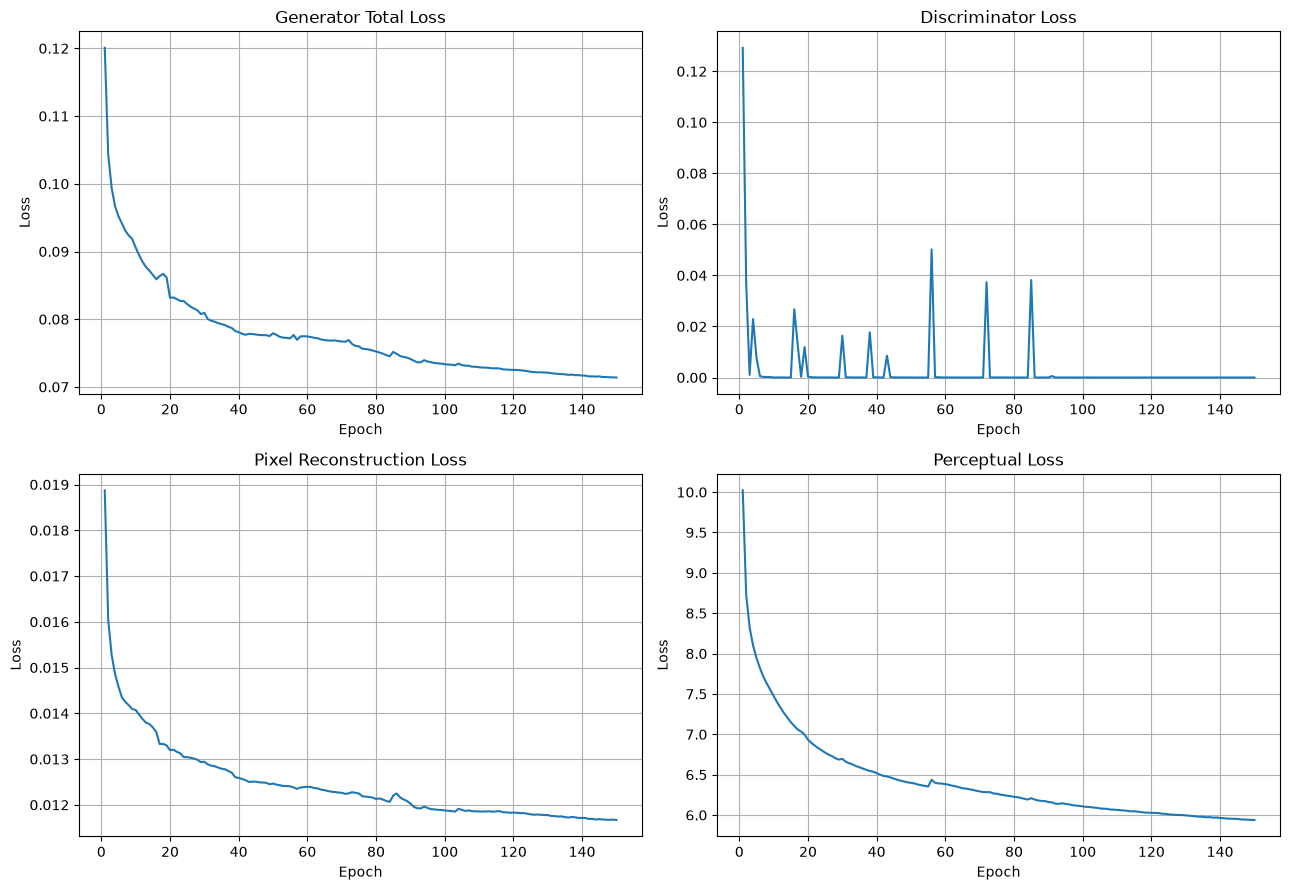

Completed epochs: 150


In [25]:
# =====================================================
# BLOCK 19: SRGAN TRAINING LOSS PLOTS
# =====================================================

import matplotlib.pyplot as plt

epochs = range(
    1,
    len(gan_history["G_loss"]) + 1
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

loss_names = [
    ("G_loss", "Generator Total Loss"),
    ("D_loss", "Discriminator Loss"),
    ("pixel_loss", "Pixel Reconstruction Loss"),
    ("perceptual_loss", "Perceptual Loss")
]

for ax, (key, title) in zip(
    axes.flatten(), loss_names
):
    ax.plot(epochs, gan_history[key])
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "srgan_training_losses.png",
    dpi=200
)

plt.show()

print("Completed epochs:", len(gan_history["G_loss"]))

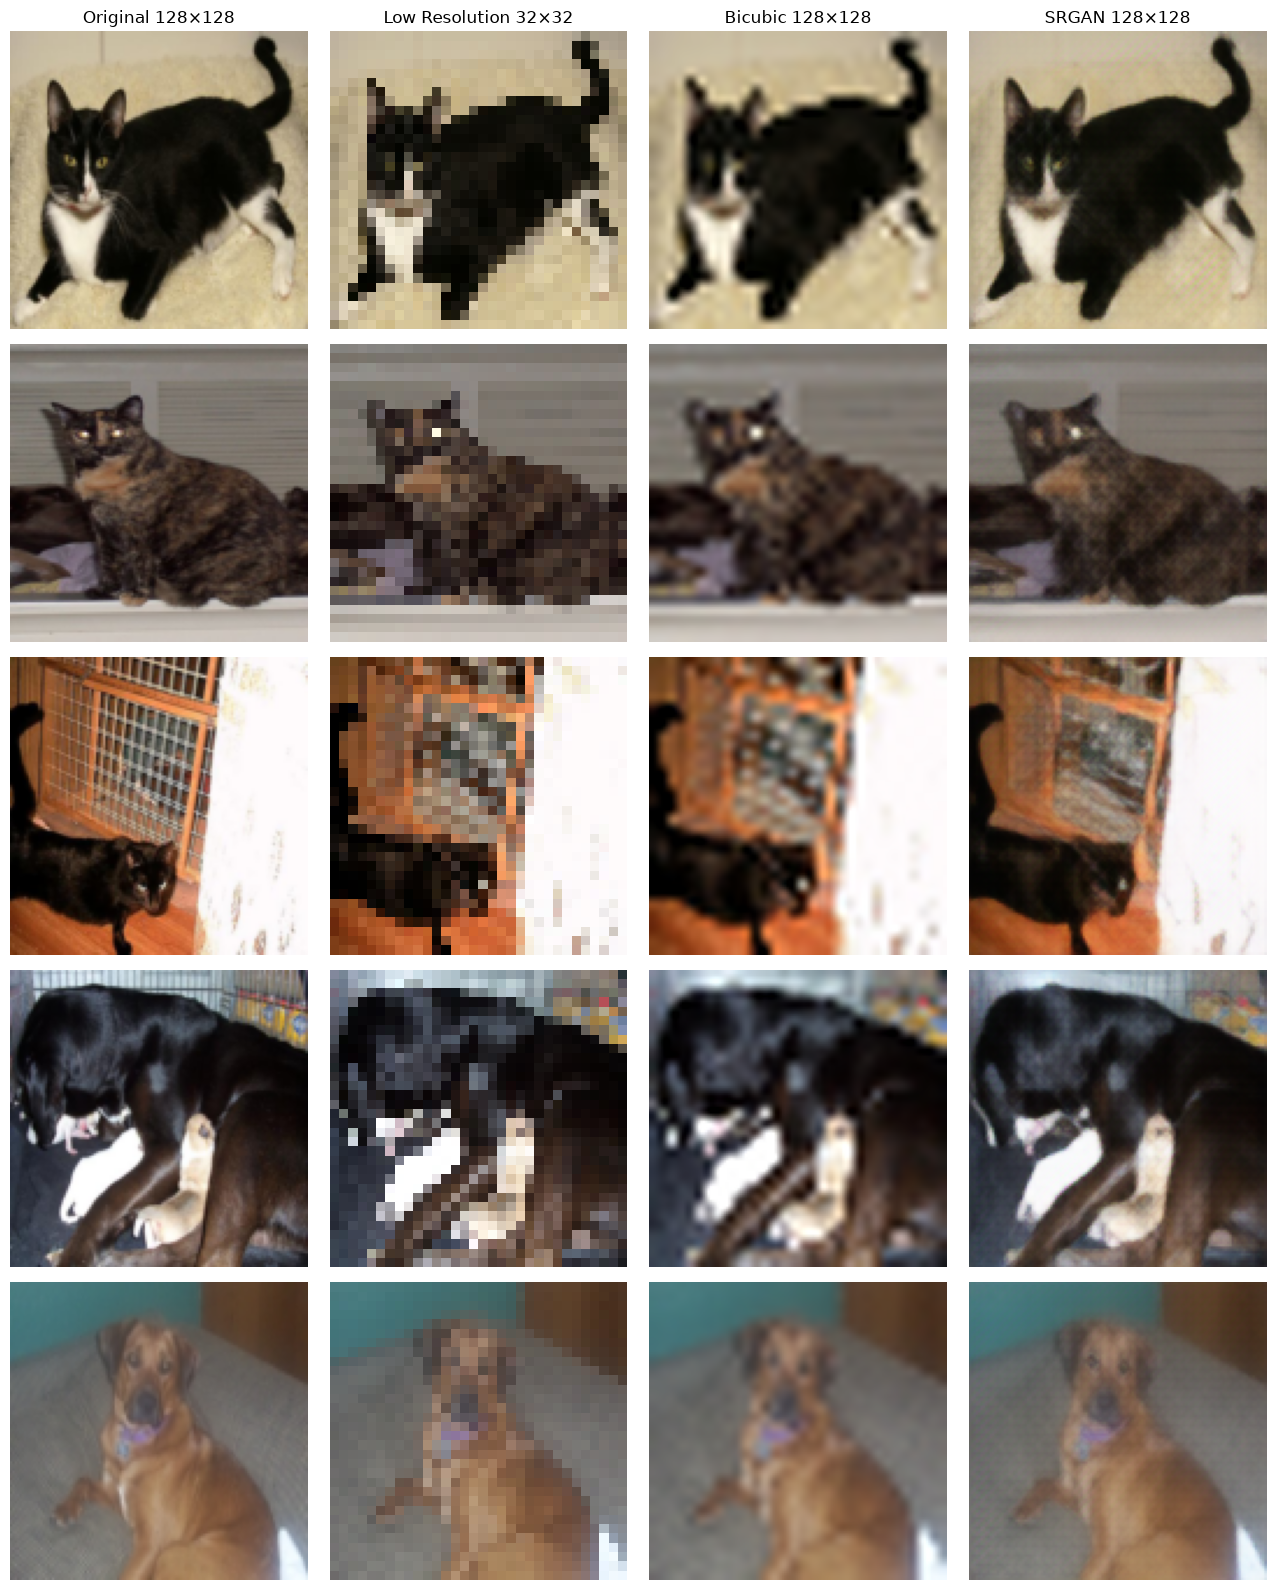

In [26]:
# =========================================================
# BLOCK 20 — SRGAN IMAGE COMPARISON
# =========================================================

generator.eval()

images, labels = next(iter(test_loader_gan))

images = images[:5].to(device)
labels = labels[:5]

lr, hr = create_lr_hr(images)

with torch.no_grad():
    sr = generator(lr)

bicubic = F.interpolate(
    lr,
    size=(128, 128),
    mode="bicubic",
    align_corners=False
).clamp(-1, 1)


def to_numpy_image(tensor):
    return (
        ((tensor.detach().cpu() + 1) / 2)
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
    )


fig, axes = plt.subplots(5, 4, figsize=(13, 16))

titles = [
    "Original 128×128",
    "Low Resolution 32×32",
    "Bicubic 128×128",
    "SRGAN 128×128"
]

for i in range(5):

    samples = [
        hr[i], lr[i], bicubic[i], sr[i]
    ]

    for j, sample in enumerate(samples):
        axes[i, j].imshow(to_numpy_image(sample))
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        "Cat" if labels[i].item() == 0 else "Dog"
    )

for ax, title in zip(axes[0], titles):
    ax.set_title(title)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "srgan_generated_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [27]:
# =========================================================
# BLOCK 21 — IMAGE QUALITY METRICS
# =========================================================

import json

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

@torch.no_grad()
def evaluate_super_resolution(generator, loader):

    generator.eval()

    measurements = {
        "Bicubic_PSNR": [],
        "Bicubic_SSIM": [],
        "SRGAN_PSNR": [],
        "SRGAN_SSIM": []
    }

    def to_numpy(x):
        return (
            ((x + 1) / 2)
            .clamp(0, 1)
            .cpu()
            .permute(0, 2, 3, 1)
            .numpy()
        )

    for images, _ in tqdm(
        loader,
        desc="Image quality evaluation"
    ):
        images = images.to(device)

        lr, hr = create_lr_hr(images)

        sr = generator(lr)

        bicubic = F.interpolate(
            lr,
            size=(128, 128),
            mode="bicubic",
            align_corners=False
        )

        hr_np = to_numpy(hr)
        sr_np = to_numpy(sr)
        bicubic_np = to_numpy(bicubic)

        for reference, generated, baseline in zip(
            hr_np, sr_np, bicubic_np
        ):
            measurements["Bicubic_PSNR"].append(
                peak_signal_noise_ratio(
                    reference, baseline, data_range=1.0
                )
            )

            measurements["SRGAN_PSNR"].append(
                peak_signal_noise_ratio(
                    reference, generated, data_range=1.0
                )
            )

            measurements["Bicubic_SSIM"].append(
                structural_similarity(
                    reference, baseline,
                    channel_axis=-1,
                    data_range=1.0
                )
            )

            measurements["SRGAN_SSIM"].append(
                structural_similarity(
                    reference, generated,
                    channel_axis=-1,
                    data_range=1.0
                )
            )

    return {
        key: float(np.mean(values))
        for key, values in measurements.items()
    }


sr_metrics = evaluate_super_resolution(
    generator,
    test_loader_gan
)

display(pd.DataFrame([sr_metrics]).round(4))

with open(
    RESULTS_DIR / "srgan_quality_metrics.json", "w"
) as f:
    json.dump(sr_metrics, f, indent=4)

torch.save(
    generator.state_dict(),
    CHECKPOINT_DIR / "generator_final.pth"
)

torch.save(
    discriminator.state_dict(),
    CHECKPOINT_DIR / "discriminator_final.pth"
)

print("SRGAN evaluation and weights saved.")

Image quality evaluation:   0%|          | 0/499 [00:00<?, ?it/s]

,Bicubic_PSNR,Bicubic_SSIM,SRGAN_PSNR,SRGAN_SSIM
0,25.1385,0.763,25.9379,0.7686


SRGAN evaluation and weights saved.


In [28]:
# =========================================================
# BLOCK 22 — RESTORE MODEL A, INITIALIZE MODEL B
# =========================================================

# Verify that 150 GAN epochs were completed.
gan_checkpoint = torch.load(
    GAN_PATH,
    map_location="cpu",
    weights_only=False
)

assert gan_checkpoint["epoch"] >= 150, (
    "Complete 150 adversarial GAN epochs before "
    "the final Classifier B experiment."
)

# Restore the final generator.
generator.load_state_dict(
    gan_checkpoint["generator"]
)

generator.eval()

for parameter in generator.parameters():
    parameter.requires_grad_(False)


# Restore best Classifier A.
classifier_A = create_classifier()

best_A_path = (
    CHECKPOINT_DIR / "classifier_A_latest_best.pth"
)

classifier_A.load_state_dict(
    torch.load(
        best_A_path,
        map_location=device,
        weights_only=True
    )
)

classifier_A.eval()


# Create independent Classifier B.
classifier_B = create_classifier()

print("Classifier A restored.")
print("Final SRGAN generator restored.")
print("Classifier B initialized.")

Classifier A restored.
Final SRGAN generator restored.
Classifier B initialized.


In [29]:
# =========================================================
# BLOCK 23 — TRAIN CLASSIFIER B
# =========================================================

CLS_EPOCHS = 10

classifier_B, history_B = fit_classifier(
    model=classifier_B,
    train_loader=train_loader_cls,
    val_loader=val_loader_cls,
    epochs=CLS_EPOCHS,
    checkpoint_path=(
        CHECKPOINT_DIR / "classifier_B_latest.pth"
    ),
    generator=generator
)

print("Classifier B training completed.")

Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 0.2764 | Train Acc: 0.8793 | Val Loss: 0.1922 | Val Acc: 0.9141


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [2/10] | Train Loss: 0.1804 | Train Acc: 0.9231 | Val Loss: 0.1902 | Val Acc: 0.9194


Training:   0%|          | 0/262 [00:00<?, ?it/s]

...

Epoch [8/10] | Train Loss: 0.1391 | Train Acc: 0.9424 | Val Loss: 0.1641 | Val Acc: 0.9291


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.1356 | Train Acc: 0.9442 | Val Loss: 0.1711 | Val Acc: 0.9216


Training:   0%|          | 0/262 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.1305 | Train Acc: 0.9447 | Val Loss: 0.1652 | Val Acc: 0.9259
Classifier B training completed.


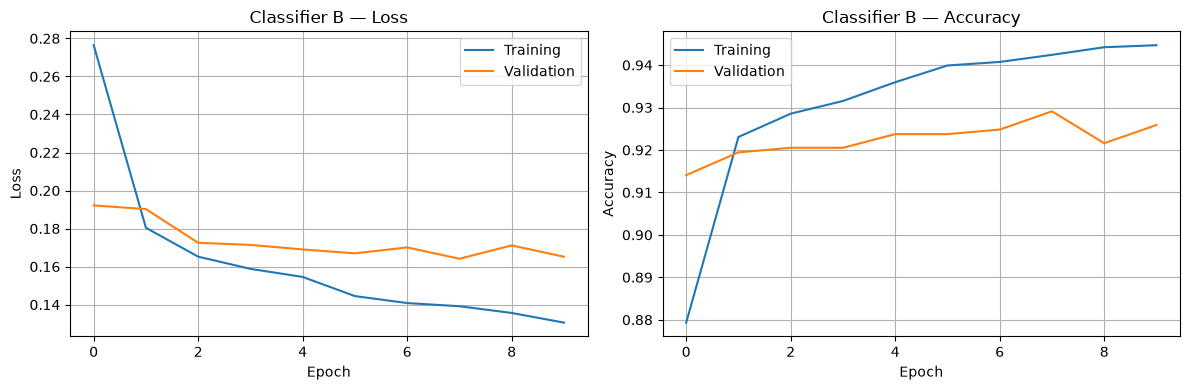

In [30]:
# =========================================================
# BLOCK 23B — CLASSIFIER B LOSS AND ACCURACY
# =========================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_B["train_loss"],
    label="Training"
)

axes[0].plot(
    history_B["val_loss"],
    label="Validation"
)

axes[0].set_title("Classifier B — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_B["train_acc"],
    label="Training"
)

axes[1].plot(
    history_B["val_acc"],
    label="Validation"
)

axes[1].set_title("Classifier B — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "classifier_B_training.png",
    dpi=200
)

plt.show()

In [31]:
# =========================================================
# BLOCK 24 — EVALUATE BOTH CLASSIFIERS
# =========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


@torch.no_grad()
def evaluate_classifier(
    model,
    loader,
    generator=None
):
    model.eval()

    if generator is not None:
        generator.eval()

    actual = []
    predicted = []
    probabilities = []

    for images, labels in tqdm(
        loader,
        desc="Classifier evaluation"
    ):
        images = images.to(device)

        inputs = get_classifier_inputs(
            images, generator
        )

        logits = model(inputs)

        probs = torch.softmax(
            logits, dim=1
        )[:, 1]

        preds = logits.argmax(dim=1)

        actual.extend(labels.numpy().tolist())
        predicted.extend(preds.cpu().numpy().tolist())
        probabilities.extend(probs.cpu().numpy().tolist())

    y_true = np.asarray(actual)
    y_pred = np.asarray(predicted)
    y_prob = np.asarray(probabilities)

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "AUC": roc_auc_score(y_true, y_prob)
    }

    return metrics, y_true, y_pred, y_prob


metrics_A, y_true_A, y_pred_A, y_prob_A = (
    evaluate_classifier(
        classifier_A,
        test_loader_cls
    )
)

metrics_B, y_true_B, y_pred_B, y_prob_B = (
    evaluate_classifier(
        classifier_B,
        test_loader_cls,
        generator=generator
    )
)

assert np.array_equal(y_true_A, y_true_B)

print("Classifier A:", metrics_A)
print("Classifier B:", metrics_B)

Classifier evaluation:   0%|          | 0/125 [00:00<?, ?it/s]

Classifier evaluation:   0%|          | 0/125 [00:00<?, ?it/s]

Classifier A: {'Accuracy': 0.9588663155254578, 'Precision': 0.9752747252747253, 'Recall': 0.9371700105596621, 'F1': 0.9558427571351642, 'AUC': 0.9946951950762613}
Classifier B: {'Accuracy': 0.927765237020316, 'Precision': 0.9294117647058824, 'Recall': 0.9176346356916578, 'F1': 0.9234856535600425, 'AUC': 0.9839084977278816}


In [32]:
# =========================================================
# BLOCK 25 — MODEL COMPARISON TABLE
# =========================================================

comparison_df = pd.DataFrame({
    "Classifier A — Original": metrics_A,
    "Classifier B — SRGAN": metrics_B
})

comparison_pct = comparison_df * 100

display(comparison_pct.round(2))

comparison_pct.to_csv(
    RESULTS_DIR / "classifier_comparison.csv"
)

with open(
    RESULTS_DIR / "classifier_metrics.json", "w"
) as f:
    json.dump(
        {
            "Classifier_A": metrics_A,
            "Classifier_B": metrics_B
        },
        f,
        indent=4
    )

,Classifier A — Original,Classifier B — SRGAN
Accuracy,95.89,92.78
Precision,97.53,92.94
Recall,93.72,91.76
F1,95.58,92.35
AUC,99.47,98.39


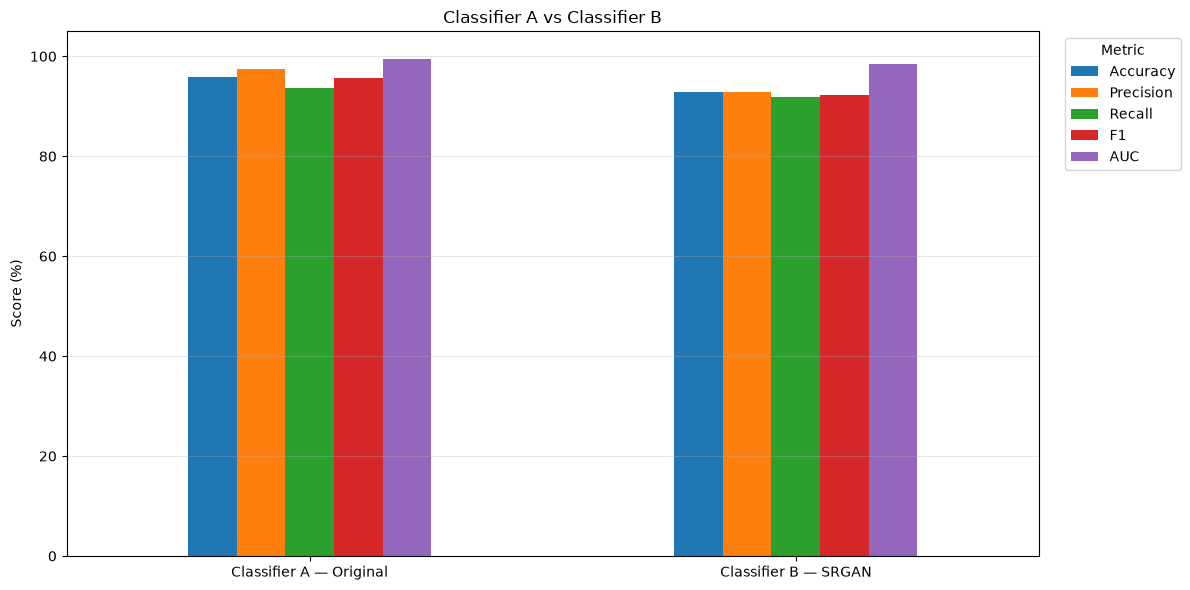

In [33]:
# =========================================================
# BLOCK 26 — MODEL COMPARISON BAR CHART
# =========================================================

ax = comparison_pct.T.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

ax.set_title("Classifier A vs Classifier B")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

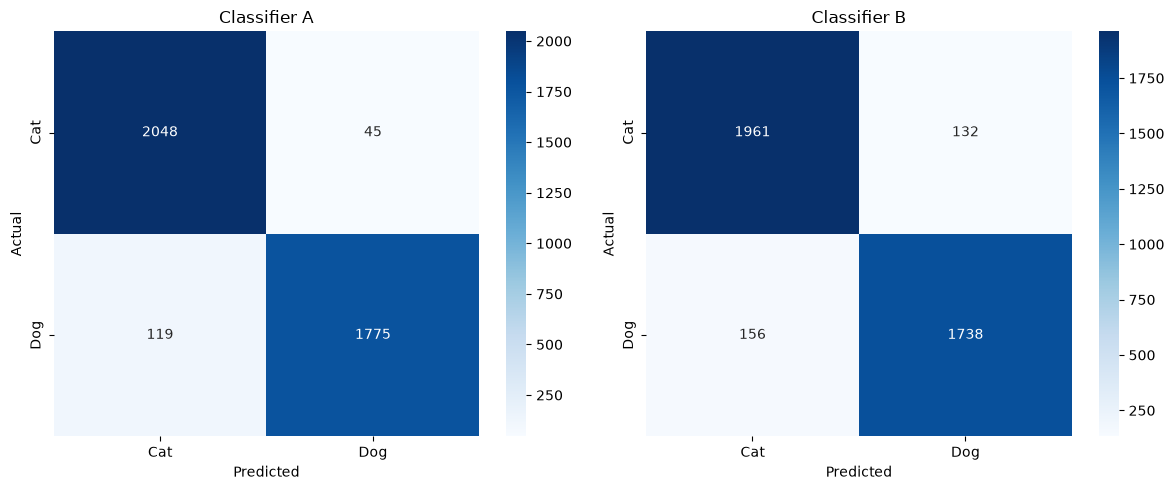

In [34]:
# =========================================================
# BLOCK 27 — CONFUSION MATRICES
# =========================================================

import seaborn as sns

cm_A = confusion_matrix(y_true_A, y_pred_A)
cm_B = confusion_matrix(y_true_B, y_pred_B)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in zip(
    axes,
    [cm_A, cm_B],
    ["Classifier A", "Classifier B"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Cat", "Dog"],
        yticklabels=["Cat", "Dog"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrices.png",
    dpi=200
)

plt.show()

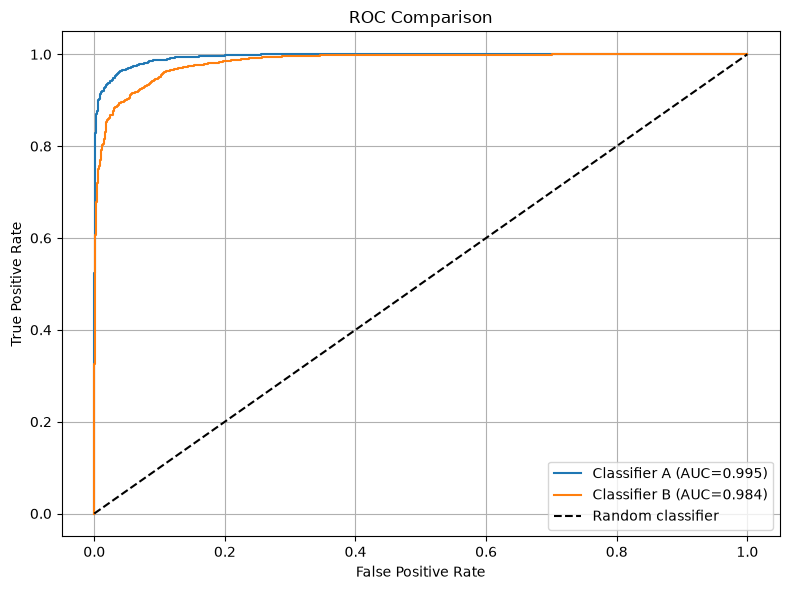


CLASSIFIER A

              precision    recall  f1-score   support

         Cat       0.95      0.98      0.96      2093
         Dog       0.98      0.94      0.96      1894

    accuracy                           0.96      3987
   macro avg       0.96      0.96      0.96      3987
weighted avg       0.96      0.96      0.96      3987


CLASSIFIER B

              precision    recall  f1-score   support

         Cat       0.93      0.94      0.93      2093
         Dog       0.93      0.92      0.92      1894

    accuracy                           0.93      3987
   macro avg       0.93      0.93      0.93      3987
weighted avg       0.93      0.93      0.93      3987



In [35]:
# =========================================================
# BLOCK 28 — ROC CURVES AND CLASSIFICATION REPORTS
# =========================================================

fpr_A, tpr_A, _ = roc_curve(
    y_true_A, y_prob_A
)

fpr_B, tpr_B, _ = roc_curve(
    y_true_B, y_prob_B
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_A, tpr_A,
    label=f"Classifier A (AUC={metrics_A['AUC']:.3f})"
)

plt.plot(
    fpr_B, tpr_B,
    label=f"Classifier B (AUC={metrics_B['AUC']:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Comparison")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "roc_comparison.png",
    dpi=200
)

plt.show()


report_A = classification_report(
    y_true_A,
    y_pred_A,
    target_names=["Cat", "Dog"]
)

report_B = classification_report(
    y_true_B,
    y_pred_B,
    target_names=["Cat", "Dog"]
)

print("\nCLASSIFIER A\n")
print(report_A)

print("\nCLASSIFIER B\n")
print(report_B)

with open(
    RESULTS_DIR / "classification_reports.txt",
    "w"
) as f:
    f.write("CLASSIFIER A\n")
    f.write(report_A)
    f.write("\nCLASSIFIER B\n")
    f.write(report_B)

In [36]:
# =========================================================
# BLOCK 29 — FINAL PROJECT VERIFICATION
# =========================================================

import json
import platform

experiment_config = {
    "project": "SRGAN Cats vs Dogs Midterm",
    "framework": "PyTorch",
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "device": str(device),
    "dataset": "Cats vs Dogs",
    "total_images": (
        len(train_df) + len(val_df) + len(test_df)
    ),
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "testing_images": len(test_df),
    "random_seed": SEED,
    "classifier_architecture": "ResNet18",
    "hr_size": IMG_SIZE,
    "lr_size": LR_SIZE,
    "srgan_generator_residual_blocks": 8,
    "srgan_upscale_factor": 4,
    "srgan_target_epochs": GAN_EPOCHS,
    "srgan_completed_epochs": len(
        gan_history["G_loss"]
    ),
    "classifier_epochs": CLS_EPOCHS,
    "generator_loss_weights": {
        "pixel": LAMBDA_PIXEL,
        "perceptual": LAMBDA_PERCEPTUAL,
        "adversarial": LAMBDA_ADV
    }
}

with open(
    PROJECT_DIR / "experiment_config.json", "w"
) as f:
    json.dump(experiment_config, f, indent=4)

required_files = [
    CHECKPOINT_DIR / "classifier_A_latest_best.pth",
    CHECKPOINT_DIR / "srgan_latest.pth",
    CHECKPOINT_DIR / "generator_final.pth",
    CHECKPOINT_DIR / "classifier_B_latest_best.pth",
    FIGURES_DIR / "image_transformations.png",
    FIGURES_DIR / "srgan_training_losses.png",
    FIGURES_DIR / "srgan_generated_examples.png",
    FIGURES_DIR / "classifier_B_training.png",
    FIGURES_DIR / "model_comparison.png",
    FIGURES_DIR / "confusion_matrices.png",
    FIGURES_DIR / "roc_comparison.png",
    RESULTS_DIR / "classifier_comparison.csv",
    RESULTS_DIR / "srgan_quality_metrics.json"
]

print("=" * 55)
print("FINAL PROJECT VERIFICATION")
print("=" * 55)

for path in required_files:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status:8s} | {path.name}")

print("\nAdversarial epochs completed:",
      len(gan_history["G_loss"]))

print("\nProject directory:", PROJECT_DIR)

FINAL PROJECT VERIFICATION
FOUND    | classifier_A_latest_best.pth
FOUND    | srgan_latest.pth
FOUND    | generator_final.pth
FOUND    | classifier_B_latest_best.pth
FOUND    | image_transformations.png
FOUND    | srgan_training_losses.png
FOUND    | srgan_generated_examples.png
FOUND    | classifier_B_training.png
FOUND    | model_comparison.png
FOUND    | confusion_matrices.png
FOUND    | roc_comparison.png
FOUND    | classifier_comparison.csv
FOUND    | srgan_quality_metrics.json

Adversarial epochs completed: 150

Project directory: /users/sbandyop/repositories/test/Applied_AI_midterm_files/SRGAN_Midterm


In [37]:
# =========================================================
# BLOCK 30 — GENERATE GITHUB README
# =========================================================

readme = f"""# SRGAN for Cats vs Dogs Binary Classification

## Overview

This project implements Super-Resolution Generative
Adversarial Networks (SRGAN) and compares two binary
classification pipelines using the Cats vs Dogs dataset.

## Dataset

- Total images: {len(train_df) + len(val_df) + len(test_df)}
- Training images: {len(train_df)}
- Validation images: {len(val_df)}
- Test images: {len(test_df)}
- Dataset split: 70% train allocation / 30% test
- Validation subset: 10% of train allocation

## Model A

A pretrained ResNet18 is trained using original
images resized to 128x128.

## SRGAN

The generator converts 32x32 RGB images into
128x128 RGB images.

Architecture:
- Generator: 8 residual blocks
- Upsampling: 2 PixelShuffle blocks
- Discriminator: convolutional binary classifier

Loss:
- Pixel MSE
- VGG16 perceptual loss
- Adversarial BCE loss

GAN epochs completed: {len(gan_history['G_loss'])}

## Model B

Classifier B uses the same ResNet18 architecture
but trains on images generated by the trained SRGAN.

## Results

| Metric | Classifier A | Classifier B |
|---|---:|---:|
| Accuracy | {metrics_A['Accuracy']:.4f} | {metrics_B['Accuracy']:.4f} |
| Precision | {metrics_A['Precision']:.4f} | {metrics_B['Precision']:.4f} |
| Recall | {metrics_A['Recall']:.4f} | {metrics_B['Recall']:.4f} |
| F1 | {metrics_A['F1']:.4f} | {metrics_B['F1']:.4f} |
| AUC | {metrics_A['AUC']:.4f} | {metrics_B['AUC']:.4f} |

## Image Reconstruction

- Bicubic PSNR: {sr_metrics['Bicubic_PSNR']:.4f}
- SRGAN PSNR: {sr_metrics['SRGAN_PSNR']:.4f}
- Bicubic SSIM: {sr_metrics['Bicubic_SSIM']:.4f}
- SRGAN SSIM: {sr_metrics['SRGAN_SSIM']:.4f}

## How to Reproduce

1. Open the Jupyter notebook on the HPC (JupyterLab or a
   scheduler job with GPU access).
2. Ensure a GPU is available (request one through your
   scheduler, e.g. salloc/sbatch with CUDA).
3. Install dependencies using the setup cell.
4. Place the Cats vs Dogs dataset in
   data/dogs-vs-cats-classification next to the notebook.
5. Run the dataset preprocessing and splitting cells.
6. Train Classifier A.
7. Pretrain the generator.
8. Train SRGAN for at least 150 adversarial epochs.
9. Train Classifier B with SRGAN-generated images.
10. Evaluate both models on the same test split.

Checkpoints are saved to the SRGAN_Midterm folder next to
the notebook and support resuming interrupted training.

## Requirements

- Python
- PyTorch
- torchvision
- NumPy
- pandas
- scikit-learn
- scikit-image
- matplotlib
- seaborn
- Pillow
- tqdm

## Figures

Generated figures include:
- Original and downscaled images
- SRGAN reconstruction examples
- GAN training losses
- Classifier training curves
- Classification metric comparison
- Confusion matrices
- ROC curves

## Reference

Ledig et al., "Photo-Realistic Single Image
Super-Resolution Using a Generative Adversarial
Network", CVPR 2017.
https://arxiv.org/abs/1609.04802
"""

README_PATH = PROJECT_DIR / "README.md"

README_PATH.write_text(
    readme,
    encoding="utf-8"
)

print("README created:", README_PATH)

README created: /users/sbandyop/repositories/test/Applied_AI_midterm_files/SRGAN_Midterm/README.md
